In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

import pandas as pd
from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles
from hnn_core.params import read_params
import sys

pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = op.join(pth, 'new_model_HNN/figures')

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255
from optimize_drives_slurm import set_params, set_params_time

with open('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/ERP/optim_time_scale_1000.pkl', 'rb') as file:
        optim = pickle.load(file)

In [2]:
write_network_configuration(optim.net_, '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/ERP/new_io_test.json')

In [3]:
net = read_network_configuration('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/ERP/new_io_test.json')

In [4]:
params = read_params('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/param/default_human_ET.json')
net_og = duecker_ET_model(params=params, add_drives_from_params=True)
og_dpl = simulate_dipole(net_og, tstop=170, n_trials=1, bsl_cor="duecker")

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Applying calcium model baseline correction


In [5]:
dpl = simulate_dipole(net, tstop=170, n_trials=1, bsl_cor="duecker")


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Applying calcium model baseline correction


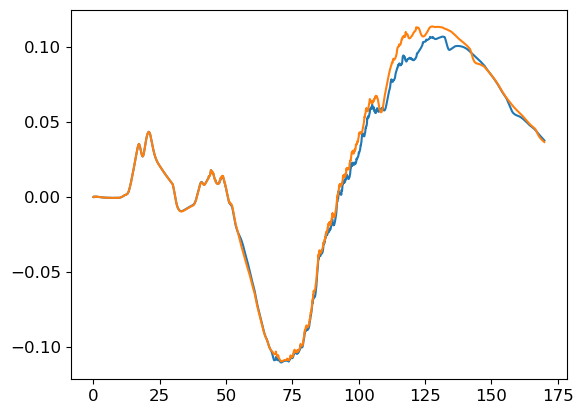

In [7]:
plt.plot(dpl[0].times,dpl[0].data['agg'])
plt.plot(og_dpl[0].times, og_dpl[0].data['agg'])

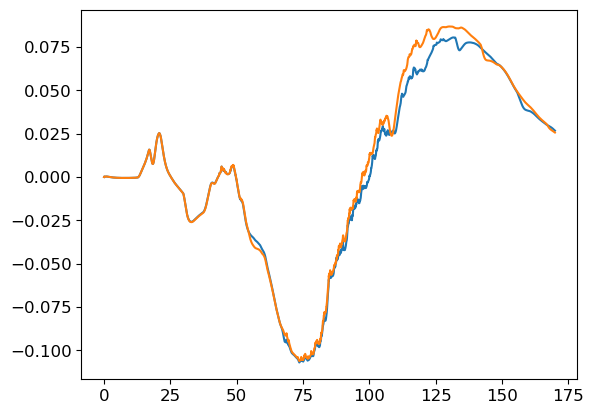

In [21]:
plt.plot(dpl[0].times,dpl[0].data['L5'])
plt.plot(og_dpl[0].times, og_dpl[0].data['L5'])

In [23]:
net.cell_types['L5_pyramidal']['cell_object'].sections['apical_tuft'].mechs == net_og.cell_types['L5_pyramidal']['cell_object'].sections['apical_tuft'].mechs

False

In [19]:
drive_og = ['evprox1', 'evdist1', 'evprox2']
drive_new = ['prox1', 'dist', 'prox2']
for dog, dnew in zip(drive_og, drive_new):
    for feature in net_og.external_drives[dog]:
        print(f'{feature} equal {net_og.external_drives[dog][feature] == net.external_drives[dnew][feature]}')

type equal True
location equal True
n_drive_cells equal True
event_seed equal True
conn_seed equal True
dynamics equal True
events equal True
weights_ampa equal True
weights_nmda equal True
synaptic_delays equal True
probability equal True
name equal False
target_types equal True
cell_specific equal True
type equal True
location equal True
n_drive_cells equal True
event_seed equal True
conn_seed equal True
dynamics equal True
events equal True
weights_ampa equal True
weights_nmda equal True
synaptic_delays equal True
probability equal True
name equal False
target_types equal True
cell_specific equal True
type equal True
location equal True
n_drive_cells equal True
event_seed equal True
conn_seed equal True
dynamics equal True
events equal True
weights_ampa equal True
weights_nmda equal True
synaptic_delays equal True
probability equal True
name equal False
target_types equal True
cell_specific equal True


In [9]:
net.external_drives

{'prox1': <External drive 'prox1'
 drive class: evoked
 target location: proximal
 target cell types: ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
 number of drive cells: 270
 cell-specific: True
 dynamic parameters:
 	mu: 16.0
 	sigma: 2.5
 	numspikes: 2
 event times instantiated for 1 trial>,
 'dist': <External drive 'dist'
 drive class: evoked
 target location: distal
 target cell types: ['L2_basket', 'L2_pyramidal', 'L5_pyramidal']
 number of drive cells: 235
 cell-specific: True
 dynamic parameters:
 	mu: 58.976201512904886
 	sigma: 2.968601372132023
 	numspikes: 4
 event times instantiated for 1 trial>,
 'prox2': <External drive 'prox2'
 drive class: evoked
 target location: proximal
 target cell types: ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
 number of drive cells: 270
 cell-specific: True
 dynamic parameters:
 	mu: 94.89656277244218
 	sigma: 11.322646413432793
 	numspikes: 4
 event times instantiated for 1 trial>}